# Mind the Stability Gap, Part 4
### An element screen: what could sit where lead sits?

**Author:** James Fox · Intro to AI & Machine Learning, Fall 2026

Lead does three jobs in a halide perovskite. Its size fits the octahedral cage, its 6s² **lone pair** makes the material forgiving of defects, and it's cheap. Any replacement has to clear chemistry *and* economics. This notebook scores ten candidate elements against seven criteria, using:
- **Geometry:** Shannon ionic radii, the octahedral factor, and the tolerance factor
- **Electronics:** whether the ion carries an ns² lone pair, and whether that oxidation state survives in air
- **Economics:** 2025 prices, supply concentration, byproduct status, and new export controls, from the USGS *Mineral Commodity Summaries 2026*
- **Safety:** a rough toxicity flag
- **Track record:** how many devices in the Perovskite Database already use each element

It's a screen, not a verdict. A screen like this is how a tech transfer office or an R&D team decides what deserves a closer look.

## 1. Setup

In [1]:
# Standard data-science stack; everything here comes pre-installed in Google Colab.
import os, re, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, KFold, cross_validate, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)

# Chart style: quiet axes and gridlines so the data does the talking
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#b5b3ab"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 11, "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})
SOURCE = "Source: The Perovskite Database (Jacobsson et al., Nature Energy 2022), CC BY 4.0"
thousands = lambda v, _: f"{v/1000:g}K" if v >= 1000 else f"{v:.0f}"

pct = lambda share: f"{share:.0%}" if share >= 0.005 else "<1%"

def save(fig, name):
    # Saves each chart as a high-resolution PNG in figures/ (ready for LinkedIn)
    fig.savefig(f"figures/{name}.png")
    plt.show()

def hbars(ax, labels, values, fmt, color=BLUE, pad=0.01, span=None):
    # Horizontal bars, top-to-bottom in the order given, with the value printed at each bar's tip
    y = np.arange(len(values))[::-1]
    ax.barh(y, values, height=0.55, color=color)
    span = span or (max(values) if max(values) > 0 else 1)
    for yi, v in zip(y, values):
        ax.text(v + span * pad, yi, fmt(v), va="center", fontsize=10, color=INK_2)
    ax.set_yticks(y, labels)
    ax.set_xlim(0, span * 1.3)
    ax.grid(axis="y", visible=False)

## 2. Get the data (for the track-record column)

In [2]:
DATA_URL = ("https://zenodo.org/records/5837035/files/"
            "Jesperkemist/perovskitedatabase_data-v1.0.1.zip?download=1")
ZIP_PATH = "perovskitedatabase_data-v1.0.1.zip"
CSV_NAME = "Perovskite_database_content_all_data.csv"

if not os.path.exists(ZIP_PATH):
    print("Downloading the Perovskite Database snapshot from Zenodo (about 3 MB)...")
    try:
        urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
    except Exception as err:
        raise RuntimeError(
            f"Download failed ({err}). Open this link in your browser:\n{DATA_URL}\n"
            "then drag the zip into Colab's Files panel (folder icon, left side) and re-run this cell.")

with zipfile.ZipFile(ZIP_PATH) as zf:
    member = next(name for name in zf.namelist() if name.endswith(CSV_NAME))
    raw = pd.read_csv(zf.open(member), low_memory=False)

print(f"Loaded {len(raw):,} devices x {raw.shape[1]} columns")
raw[["Ref_DOI_number", "Ref_publication_date", "Cell_architecture",
     "Perovskite_composition_short_form", "JV_default_PCE", "Stability_measured"]].head()

Loaded 42,443 devices x 410 columns


,Ref_DOI_number,Ref_publication_date,Cell_architecture,Perovskite_composition_short_form,JV_default_PCE,Stability_measured
0,10.1021/jp5126624,2015-01-06,nip,CsSnI,0.00,False
1,10.1021/jp5126624,2015-01-06,nip,CsSnBrI,0.00,False
2,10.1021/jp5126624,2015-01-06,nip,CsSnBrI,0.13,False
3,10.1021/jp5126624,2015-01-06,nip,CsSnBrI,0.12,False
4,10.1021/jp5126624,2015-01-06,nip,CsSnBr,0.10,False


In [3]:
MISSING = {"", "nan", "none", "unknown", "n/a", "na", "-"}

def get(name):
    # Returns a column, or an all-empty column if this snapshot doesn't have it
    return raw[name] if name in raw.columns else pd.Series(np.nan, index=raw.index)

def reported(series):
    # True where a cell holds real information rather than one of the 'missing' markers
    def check(v):
        if pd.isna(v):
            return False
        return any(tok.strip().lower() not in MISSING for tok in re.split(r"[;|>]+", str(v)))
    return series.map(check).astype(bool)

def to_bool(series):
    return series.astype(str).str.strip().str.lower().isin(["true", "1", "yes"])

def to_num(series):
    # Numbers stay numbers; text like '1.6 | nan' falls back to its first number
    direct = pd.to_numeric(series, errors="coerce")
    first = pd.to_numeric(series.astype(str).str.extract(r"(-?\d+(?:\.\d+)?)")[0], errors="coerce")
    return direct.fillna(first)

def range_max(series):
    # Largest number in a 'min; max' range ('25; 85' -> 85)
    def f(v):
        nums = re.findall(r"-?\d+(?:\.\d+)?", str(v))
        return max(map(float, nums)) if nums else np.nan
    return series.map(f)

def text(series):
    return series.where(reported(series), "").astype(str).str.strip().str.lower()

def atmosphere_group(v):
    tokens = {t.strip() for t in re.split(r"[;|]", v) if t.strip()}
    if not tokens:
        return "Not reported"
    if tokens <= {"n2", "ar", "argon", "vacuum", "he", "inert"}:
        return "Inert (N2/Ar/vacuum)"
    if "dry air" in tokens:
        return "Dry air"
    if tokens & {"air", "ambient"}:
        return "Air / ambient"
    return "Other"

def bias_group(v):
    if not v:
        return "Not reported"
    for key, label in [("mpp", "MPP tracking"), ("open", "Open circuit"),
                       ("short", "Short circuit"), ("constant", "Constant bias")]:
        if key in v:
            return label
    return "Other"

TEST_TYPES = {  # ISOS category -> plain-English test type (conditions from Khenkin et al. 2020, Table 1)
    "d1": "Dark, room temperature (shelf life)",
    "d2": "Dark, heated to 65-85 °C",
    "d3": "Dark, 65-85 °C and 85% humidity (damp heat)",
    "l1": "Under light, room temperature",
    "l2": "Under light, heated to 65-85 °C",
    "l3": "Under light, heated, ~50% humidity",
    "o":  "Outdoors",
}
def test_type(v):
    v = v.replace("‐", "-").replace("‑", "-").replace(" ", "")   # some entries use unicode hyphens
    if not v:
        return "Not classified"
    m = re.match(r"isos-(lc|[dlotv])-?(\d)", v)
    if not m:
        return "Cycling, bias, IEC or other"
    kind = m.group(1) if m.group(1) == "o" else m.group(1) + m.group(2)
    return TEST_TYPES.get(kind, "Cycling, bias, IEC or other")

## 3. The candidates

Each element appears in the oxidation state relevant to perovskite chemistry. Prices are converted from USGS units to dollars per kilogram, and their grades differ: boron's price is for raw imported borates, not refined boron. So read them as orders of magnitude.

**The lone-pair diagonal.** The ns² ions sit on a diagonal of the periodic table: Tl⁺, Pb²⁺, and Bi³⁺ (6s²); In⁺, Sn²⁺, and Sb³⁺ (5s²); Ga⁺, Ge²⁺, and As³⁺ (4s²). Ganose, Savory & Scanlon (2017) argue this electron configuration is the main reason lead perovskites are so defect tolerant.

In [4]:
LB_PER_KG, OZT_PER_KG = 2.20462, 32.1507
TO_USD_PER_KG = {"cents/lb": LB_PER_KG / 100, "$/lb": LB_PER_KG, "$/kg": 1.0, "$/troy oz": OZT_PER_KG, "$/t": 1 / 1000}

# radius: Shannon (1976) six-coordinate ionic radius in Å (Sn²⁺ is not in Shannon's table; 1.10 Å is a commonly used estimate)
# price, top producer, byproduct and export controls: USGS Mineral Commodity Summaries 2026 (2025 estimates)
# crust: crustal abundance in mg/kg (CRC Handbook)
rows = [
 # sym, ion, radius, lone pair, ox. state stable in air, crust, price, unit, top producer, share, byproduct, export controls since 2023, hazard
 ("Pb", "Pb²⁺", 1.19, True,  True,  14,     106,  "cents/lb",  "China",  0.42, "partly (mined with zinc)",      "none reported",                   "high"),
 ("Sn", "Sn²⁺", 1.10, True,  False, 2.3,    1600, "cents/lb",  "China",  0.24, "no (mined directly)",           "none reported",                   "lower"),
 ("Ge", "Ge²⁺", 0.73, True,  False, 1.5,    4100, "$/kg",      "China",  np.nan, "yes (zinc ores, coal)",       "China 2023; US ban Dec 2024",     "lower"),
 ("Bi", "Bi³⁺", 1.03, True,  True,  0.0085, 20,   "$/lb",      "China",  0.88, "yes (lead ores)",               "China 2025",                      "lower"),
 ("Sb", "Sb³⁺", 0.76, True,  True,  0.2,    25,   "$/lb",      "China",  0.36, "no (mostly mined directly)",    "China 2024; US ban Dec 2024",     "moderate"),
 ("As", "As³⁺", 0.58, True,  True,  1.8,    1.85, "$/lb",      "Peru",   0.49, "yes (smelter residues)",        "none reported",                   "high"),
 ("In", "In³⁺", 0.80, False, True,  0.25,   380,  "$/kg",      "China",  0.70, "yes (zinc ores)",               "China 2025",                      "moderate"),
 ("Ga", "Ga³⁺", 0.62, False, True,  19,     580,  "$/kg",      "China",  0.99, "yes (bauxite)",                 "China 2023; US ban Dec 2024 (paused Nov 2025)", "lower"),
 ("Ag", "Ag⁺",  1.15, False, True,  0.075,  38,   "$/troy oz", "Mexico", 0.24, "yes (lead-zinc, copper, gold)", "none reported",                   "lower"),
 ("B",  "B³⁺",  0.27, False, True,  10,     540,  "$/t",       "Turkey", 0.51, "no (borate mines)",             "none reported",                   "lower"),
]
el = pd.DataFrame(rows, columns=["element", "ion", "radius_A", "lone_pair", "ox_state_stable", "crust_mg_per_kg",
                                 "price", "price_unit", "top_producer", "top_share", "byproduct",
                                 "export_controls", "hazard"]).set_index("element")
el["usd_per_kg"] = el["price"] * el["price_unit"].map(TO_USD_PER_KG)

# How many devices in the Perovskite Database use each metal at the B-site
b_tokens = get("Perovskite_composition_b_ions").fillna("").astype(str).map(
    lambda s: {t.strip().strip("()") for t in re.split(r"[;|]", s) if t.strip()})
el["devices_in_database"] = [int(b_tokens.map(lambda t: sym in t).sum()) for sym in el.index]

el[["ion", "radius_A", "lone_pair", "crust_mg_per_kg", "usd_per_kg", "top_producer", "top_share",
    "byproduct", "export_controls", "devices_in_database"]].style.format(
    {"radius_A": "{:.2f}", "crust_mg_per_kg": "{:g}", "usd_per_kg": "${:,.2f}", "top_share": "{:.0%}",
     "devices_in_database": "{:,}"}, na_rep="not reported")

,ion,radius_A,lone_pair,crust_mg_per_kg,usd_per_kg,top_producer,top_share,byproduct,export_controls,devices_in_database
element,,,,,,,,,,
Pb,Pb²⁺,1.19,True,14,$2.34,China,42%,partly (mined with zinc),none reported,"41,372"
Sn,Sn²⁺,1.10,True,2.3,$35.27,China,24%,no (mined directly),none reported,"1,154"
Ge,Ge²⁺,0.73,True,1.5,"$4,100.00",China,not reported,"yes (zinc ores, coal)",China 2023; US ban Dec 2024,21
Bi,Bi³⁺,1.03,True,0.0085,$44.09,China,88%,yes (lead ores),China 2025,305
Sb,Sb³⁺,0.76,True,0.2,$55.12,China,36%,no (mostly mined directly),China 2024; US ban Dec 2024,131
As,As³⁺,0.58,True,1.8,$4.08,Peru,49%,yes (smelter residues),none reported,0
In,In³⁺,0.80,False,0.25,$380.00,China,70%,yes (zinc ores),China 2025,5
Ga,Ga³⁺,0.62,False,19,$580.00,China,99%,yes (bauxite),China 2023; US ban Dec 2024 (paused Nov 2025),0
Ag,Ag⁺,1.15,False,0.075,"$1,221.73",Mexico,24%,"yes (lead-zinc, copper, gold)",none reported,9


## 4. Does it fit? Geometry with iodide, bromide, and chloride

Two checks, both from ionic radii:
- **Octahedral factor μ = r_B / r_X ≥ 0.41:** is the metal big enough to hold six halides around it?
- **Tolerance factor 0.8 ≤ t ≤ 1.0** (with Cs⁺ at the A-site): do the pieces stack into a 3D framework?

Trivalent ions like Bi³⁺ can't simply replace Pb²⁺, because the charges wouldn't balance. Instead, they pair with a monovalent ion in a **double perovskite**, Cs₂B⁺B³⁺X₆, the way Cs₂AgBiBr₆ does. For those, the geometry uses the average radius of the pair, with Ag⁺ as the partner (and Bi³⁺ as the partner for Ag⁺).

In [5]:
R_CS = 1.88
R_X = {"I": 2.20, "Br": 1.96, "Cl": 1.81}
PARTNER = {"Bi": "Ag", "Sb": "Ag", "As": "Ag", "In": "Ag", "Ga": "Ag", "B": "Ag", "Ag": "Bi"}

geo_rows = []
for sym, row in el.iterrows():
    partner = PARTNER.get(sym)
    r_b = row["radius_A"] if partner is None else (row["radius_A"] + el.loc[partner, "radius_A"]) / 2
    structure = "CsBX₃" if partner is None else f"Cs₂{'Ag' if sym != 'Ag' else ''}{sym}{'Bi' if sym == 'Ag' else ''}X₆"
    entry = {"element": sym, "structure": structure}
    for x, r_x in R_X.items():
        mu = r_b / r_x
        t = (R_CS + r_x) / (np.sqrt(2) * (r_b + r_x))
        entry[f"μ ({x})"], entry[f"t ({x})"] = mu, t
        entry[f"fits ({x})"] = (mu >= 0.41) and (0.8 <= t <= 1.0)
    fitting = [x for x in R_X if entry[f"fits ({x})"]]
    entry["fits with"] = ", ".join(fitting) if fitting else "none"
    geo_rows.append(entry)
geo = pd.DataFrame(geo_rows).set_index("element")
el["geometry_ok"] = geo["fits with"] != "none"

def shade_fit(v):
    return "background-color: #cde2fb" if v != "none" else "color: #898781"
geo[["structure", "μ (I)", "t (I)", "μ (Br)", "t (Br)", "μ (Cl)", "t (Cl)", "fits with"]].style.format(
    {c: "{:.2f}" for c in geo.columns if c.startswith(("μ", "t ("))}).map(shade_fit, subset=["fits with"])

,structure,μ (I),t (I),μ (Br),t (Br),μ (Cl),t (Cl),fits with
element,,,,,,,,
Pb,CsBX₃,0.54,0.85,0.61,0.86,0.66,0.87,"I, Br, Cl"
Sn,CsBX₃,0.50,0.87,0.56,0.89,0.61,0.90,"I, Br, Cl"
Ge,CsBX₃,0.33,0.98,0.37,1.01,0.40,1.03,none
Bi,Cs₂AgBiX₆,0.50,0.88,0.56,0.89,0.60,0.90,"I, Br, Cl"
Sb,Cs₂AgSbX₆,0.43,0.91,0.49,0.93,0.53,0.94,"I, Br, Cl"
As,Cs₂AgAsX₆,0.39,0.94,0.44,0.96,0.48,0.98,"Br, Cl"
In,Cs₂AgInX₆,0.44,0.91,0.50,0.93,0.54,0.94,"I, Br, Cl"
Ga,Cs₂AgGaX₆,0.40,0.94,0.45,0.95,0.49,0.97,"Br, Cl"
Ag,Cs₂AgBiX₆,0.50,0.88,0.56,0.89,0.60,0.90,"I, Br, Cl"


**What the geometry says.**
- **Boron fails at every halide**, even when averaged with silver. It's simply too small for an octahedral cage.
- **Germanium technically passes the tolerance factor but fails the octahedral factor.** That matches experiment: germanium perovskites form, but badly distorted.
- **Arsenic fits only as half of a double perovskite with bromide or chloride**, and only just.
- **Gallium and indium fit only with chloride.** Cs₂AgInCl₆ is a real compound, but chloride pushes the band gap far too wide for a single-junction solar cell.

## 5. The scorecard

Seven pass/fail checks. A "?" means the data isn't public.
1. **Fits the geometry** with at least one halide (section 4)
2. **Has an ns² lone pair**, the lead-like electronic feature
3. **Oxidation state survives in air.** Sn²⁺ and Ge²⁺ oxidize to the 4+ state. In⁺, the lone-pair form of indium, oxidizes to In³⁺ (Xiao *et al.*, *JACS* 2017), which is why indium appears here as In³⁺.
4. **Price under $100/kg** (2025)
5. **No country above 50%** of world production
6. **No new export controls since 2023**
7. **Lower toxicity concern.** Rough screening labels: lead and arsenic are flagged high (lead is restricted in EU electronics, and inorganic arsenic is a known human carcinogen). Antimony and indium are moderate, since some of their compounds are classed as probable carcinogens.

,Fits geometry,ns² lone pair,Stable oxidation state,Under $100/kg,No country >50%,No new export controls,Lower toxicity,Score (of 7),Devices in database
element,,,,,,,,,
Pb,✓,✓,✓,✓,✓,✓,✗,6,"41,372"
Sn,✓,✓,✗,✓,✓,✓,✓,6,"1,154"
As,✓,✓,✓,✓,✓,✓,✗,6,0
Bi,✓,✓,✓,✓,✗,✗,✓,5,305
Sb,✓,✓,✓,✓,✓,✗,✗,5,131
Ag,✓,✗,✓,✗,✓,✓,✓,5,9
B,✗,✗,✓,✓,✗,✓,✓,4,0
Ga,✓,✗,✓,✗,✗,✗,✓,3,0
Ge,✗,✓,✗,✗,?,✗,✓,2,21


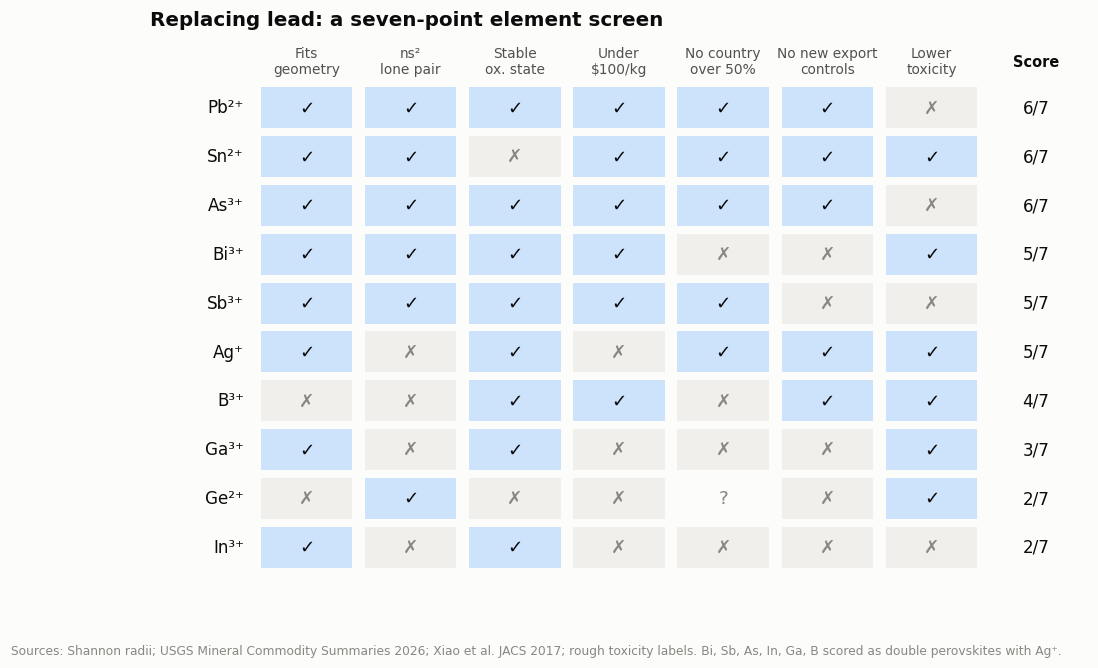

In [6]:
CRITERIA = {
    "Fits geometry": el["geometry_ok"],
    "ns² lone pair": el["lone_pair"],
    "Stable oxidation state": el["ox_state_stable"],
    "Under $100/kg": el["usd_per_kg"] < 100,
    "No country >50%": el["top_share"].map(lambda s: None if pd.isna(s) else s <= 0.5),
    "No new export controls": el["export_controls"].eq("none reported"),
    "Lower toxicity": el["hazard"].eq("lower"),
}
score = pd.DataFrame(CRITERIA)
score["Score (of 7)"] = score.apply(lambda r: sum(v is True or v == True for v in r if v is not None), axis=1)
score["Devices in database"] = el["devices_in_database"]
score = score.sort_values(["Score (of 7)", "Devices in database"], ascending=False)

def mark(v):
    if v is None or (isinstance(v, float) and np.isnan(v)): return "?"
    return "✓" if bool(v) else "✗"
display(score.style.format({**{c: mark for c in CRITERIA}, "Devices in database": "{:,}"}))

# A picture of the scorecard for sharing
HEADERS = ["Fits\ngeometry", "ns²\nlone pair", "Stable\nox. state", "Under\n$100/kg", "No country\nover 50%",
           "No new export\ncontrols", "Lower\ntoxicity"]
fig, ax = plt.subplots(figsize=(11, 0.5 * len(score) + 1.4))
ax.set_xlim(0, len(CRITERIA) + 2); ax.set_ylim(len(score) - 0.4, -1.5); ax.axis("off")
for j, header in enumerate(HEADERS):
    ax.text(j + 1.5, -0.95, header, ha="center", va="center", fontsize=9, color=INK_2)
ax.text(len(CRITERIA) + 1.5, -0.95, "Score", ha="center", va="center", fontsize=9.5, color=INK, fontweight="bold")
for i, (sym, r) in enumerate(score.iterrows()):
    ax.text(0.9, i, f"{el.loc[sym, 'ion']}", ha="right", va="center", fontsize=11, color=INK)
    for j, crit in enumerate(CRITERIA):
        v = r[crit]
        known = v is not None and not (isinstance(v, float) and np.isnan(v))
        face = "#cde2fb" if known and bool(v) else ("#f0efec" if known else SURFACE)
        ax.add_patch(plt.Rectangle((j + 1.06, i - 0.42), 0.88, 0.84, color=face, lw=0))
        ax.text(j + 1.5, i, mark(v), ha="center", va="center", fontsize=12,
                color=INK if (known and bool(v)) else MUTED)
    ax.text(len(CRITERIA) + 1.5, i, f"{r['Score (of 7)']}/7", ha="center", va="center", fontsize=11, color=INK)
ax.set_title("Replacing lead: a seven-point element screen", loc="left", pad=6)
fig.text(0.01, 0.0, "Sources: Shannon radii; USGS Mineral Commodity Summaries 2026; Xiao et al. JACS 2017; rough toxicity labels. "
         "Bi, Sb, As, In, Ga, B scored as double perovskites with Ag⁺.", fontsize=8, color=MUTED)
save(fig, "13_element_scorecard")

## 6. Rarity is not the same as price

Plotting price against how common each element is in Earth's crust shows that **supply chains, not geology, set most of these prices.**

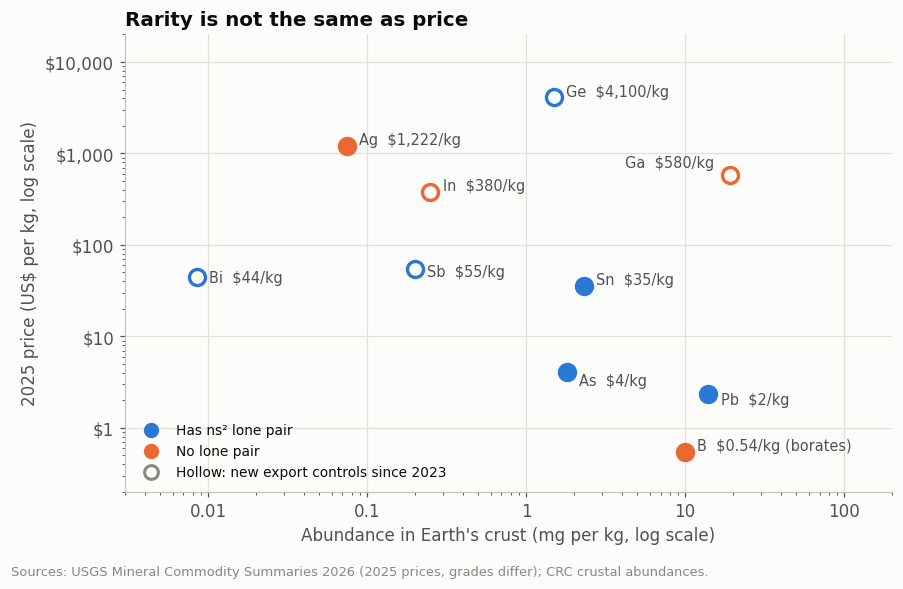

In [7]:
fig, ax = plt.subplots(figsize=(9, 5.4))
for sym, r in el.iterrows():
    color = BLUE if r["lone_pair"] else ORANGE
    controlled = r["export_controls"] != "none reported"
    ax.scatter(r["crust_mg_per_kg"], r["usd_per_kg"], s=110, zorder=3,
               facecolor=SURFACE if controlled else color, edgecolor=color, linewidth=2.2)
OFFSETS = {"Pb": (8, -4), "Sn": (8, 4), "Ge": (8, 4), "Bi": (8, 0), "Sb": (8, -2), "As": (8, -6),
           "In": (8, 4), "Ga": (-10, 8), "Ag": (8, 4), "B": (8, 4)}
for sym, r in el.iterrows():
    dx, dy = OFFSETS.get(sym, (8, 0))
    ax.annotate(f"{sym}  ${r['usd_per_kg']:,.0f}/kg" if r["usd_per_kg"] >= 1 else f"{sym}  ${r['usd_per_kg']:.2f}/kg (borates)",
                (r["crust_mg_per_kg"], r["usd_per_kg"]), xytext=(dx, dy), textcoords="offset points",
                ha="right" if dx < 0 else "left", va="center", fontsize=9.5, color=INK_2)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(0.003, 200); ax.set_ylim(0.2, 20000)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:g}")
ax.yaxis.set_major_formatter(lambda v, _: f"${v:,.0f}" if v >= 1 else f"${v:g}")
ax.set_xlabel("Abundance in Earth's crust (mg per kg, log scale)")
ax.set_ylabel("2025 price (US$ per kg, log scale)")
ax.set_title("Rarity is not the same as price")
from matplotlib.lines import Line2D
handles = [Line2D([], [], marker="o", ls="", ms=9, mfc=BLUE, mec=BLUE, label="Has ns² lone pair"),
           Line2D([], [], marker="o", ls="", ms=9, mfc=ORANGE, mec=ORANGE, label="No lone pair"),
           Line2D([], [], marker="o", ls="", ms=9, mfc=SURFACE, mec=MUTED, mew=2, label="Hollow: new export controls since 2023")]
ax.legend(handles=handles, frameon=False, loc="lower left", fontsize=9)
fig.text(0.01, -0.03, "Sources: USGS Mineral Commodity Summaries 2026 (2025 prices, grades differ); CRC crustal abundances.",
         fontsize=8.5, color=MUTED)
save(fig, "14_rarity_vs_price")

**Reading the map.**
- **Gallium is more common than lead** (19 vs 14 mg/kg), yet costs about 250× more. It's recovered as a byproduct of aluminum production, and China produces about 99% of it.
- **Bismuth is one of the rarest elements here,** yet costs only about $44/kg, because it comes out of lead refining. That same dependence is why China controls 88% of it.
- **Arsenic is about as common as germanium,** but costs roughly 1,000× less: about $4/kg versus $4,100/kg.
- **Hollow markers are the elements China placed under export controls between 2023 and 2025:** germanium, gallium, antimony, indium, and bismuth, five of the ten candidates.

## 7. Where this points

**The top tier is lead, tin, and arsenic, each at 6 of 7.** Each fails exactly one check, and it's a serious one: lead and arsenic are toxic, and tin oxidizes from Sn²⁺ to Sn⁴⁺ in air. The bismuth and antimony double perovskites come next. They pass most checks but carry supply-concentration and export-control risk.

**Arsenic is the surprise.** It scores well on geometry, lone pair, price, and supply, and fails only on toxicity. That one failure matters enormously for a consumer product. Still, arsenic is already part of the most efficient solar cells ever made: a four-junction III–V cell built from gallium, indium, arsenic, and phosphorus compounds reached 47.6% (Fraunhofer ISE, 2022). Those cells are grown by slow, expensive epitaxy, which is exactly the cost problem perovskites were meant to solve.

**Gallium is odd for a real reason.** Its filled 3d shell shields the nucleus poorly, so gallium ends up smaller and *more* electronegative than aluminum above it. In solar it's a dopant and alloying element, not a framework metal: it replaced boron in silicon wafers and tunes the band gap of CIGS cells.

**For harder bonds with iodide-like electronegativity, change the anion instead of the metal.** Sulfur's electronegativity (2.58) is close to iodine's (2.66), but S²⁻ carries twice the charge, so its bonds are stronger. **Chalcogenide perovskites** like BaZrS₃ have a ~1.8 eV gap (good for tandem top cells), stay stable in air up to at least 400 °C, and are made entirely of elements among the 20 most abundant in Earth's crust. The catch is the very high processing temperature. This is the kind of material David Mitzi's group at Duke works on.

**Limits of this screen:** radii treat ions as hard spheres, prices are single-year snapshots at mixed grades, toxicity labels are rough, and passing a screen says nothing about efficiency.

In [8]:
s4 = {"top_scores": ", ".join(f"{s} {int(v)}/7" for s, v in score["Score (of 7)"].head(4).items()),
      "gallium_vs_lead_price_ratio": el.loc["Ga", "usd_per_kg"] / el.loc["Pb", "usd_per_kg"],
      "germanium_vs_arsenic_price_ratio": el.loc["Ge", "usd_per_kg"] / el.loc["As", "usd_per_kg"]}
pd.Series(s4).to_csv("part4_summary.csv", header=["value"])
print(score[["Score (of 7)", "Devices in database"]].to_string())

         Score (of 7)  Devices in database
element                                   
Pb                  6                41372
Sn                  6                 1154
As                  6                    0
Bi                  5                  305
Sb                  5                  131
Ag                  5                    9
B                   4                    0
Ga                  3                    0
Ge                  2                   21
In                  2                    5


## Sources
- Shannon, R.D. Revised effective ionic radii. *Acta Cryst.* A32, 751–767 (1976), via pymatgen.
- U.S. Geological Survey, *Mineral Commodity Summaries 2026*: lead, tin, germanium, bismuth, antimony, arsenic, indium, gallium, silver, boron.
- Ganose, Savory & Scanlon, Beyond methylammonium lead iodide: prospects for the emergent field of ns² containing solar absorbers, *Chem. Commun.* (2017), [doi:10.1039/c6cc06475b](https://doi.org/10.1039/c6cc06475b).
- Xiao *et al.*, Intrinsic instability of Cs₂In(I)M(III)X₆ double perovskites, *J. Am. Chem. Soc.* 139 (2017).
- Comparotto *et al.*, Thermodynamic insights into the Ba–S system for BaZrS₃, RSC (2025), [doi:10.1039/d5ta00798d](https://doi.org/10.1039/d5ta00798d).
- Fraunhofer ISE four-junction III–V cell, 47.6% (2022).